# Selected High- and Low-Relevance Firms on the Main Relevance Score, Colored by Sector

| Item | Description |
|---|---|
| Goal | Generate a standalone, publication-ready figure and a compact CSV dataset for a selected subsample of prominent high-relevance and low-relevance firms on the main topic relevance measure (cosine similarity between firm-level 10-K Item 1 summaries and the congressional policy summary). |
| Input |  (wide relevance scores);  (Compustat NAICS codes); or directly . |
| Output |  (compact CSV of the 18 selected firms with scores, demeaned scores, and NAICS sectors) and . |
| Selected Firms | **High Side (14 firms)**: Visa, Nielsen, Alphabet, Verizon, Qualcomm, Cisco, Apple, Allstate, Amazon, Equifax, Microsoft, Mastercard, Oracle, GE Healthcare.<br>**Low Side (4 firms)**: Kansas City Southern, Morgan Stanley, Norwegian Cruise Line Holdings, Pepsi Bottling Group. |
| Measure |  demeaned by the sample mean over all 1,058 firms (0.5121). |


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.patches import Patch


## Step 2. Define file locations, the measure, the industry names, and the wording

The wording is built from the same two phrases as T3.9.1 to T3.9.3. The subsector names are NAICS 2022 names, shortened where a name is long; codes that exist only in older NAICS vintages are named by that vintage.


In [2]:
from pathlib import Path

# Paths relative to repository root for local execution and GitHub compatibility
NOTEBOOK_DIR = Path.cwd()
# If executed from inside this directory or project root
PROJECT_FOLDER = NOTEBOOK_DIR if (NOTEBOOK_DIR / "T3 - Topic Relevance and Corporate Disclosure").exists() else NOTEBOOK_DIR.parents[2]
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.9.5"
TEMP_OUTPUT = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output"
OUTPUT_FOLDER = TEMP_OUTPUT / NOTEBOOK_NAME
SCORES_FILE = TEMP_OUTPUT / "T3.8.3/firm_relevance_scores_wide.csv"
CONTROLS_FILE = PROJECT_FOLDER / "T4 - Toy Example [Topic Relevance on Privacy Innovation]/compustat/compustat_controls.csv"
SELECTED_CSV_FILE = OUTPUT_FOLDER / "selected_firms_relevance_scores.csv"

SAMPLE = "all_years"
MEASURE_ID = "summaries | policy_summary | firm_summary"

NAICS_SECTORS = {
    "11": "Agriculture, forestry, fishing and hunting", "21": "Mining, quarrying, and oil and gas extraction", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing", "42": "Wholesale trade", "44": "Retail trade", "45": "Retail trade",
    "48": "Transportation and warehousing", "49": "Transportation and warehousing", "51": "Information", "52": "Finance and insurance",
    "53": "Real estate and rental and leasing", "54": "Professional, scientific, and technical services", "55": "Management of companies and enterprises",
    "56": "Administrative and support and waste management", "61": "Educational services", "62": "Health care and social assistance",
    "71": "Arts, entertainment, and recreation", "72": "Accommodation and food services", "81": "Other services (except public administration)"
}

NAICS_SUBSECTORS = {
    "111": "Crop Production", "112": "Animal Production and Aquaculture", "113": "Forestry and Logging", "114": "Fishing, Hunting and Trapping", "115": "Support Activities for Agriculture and Forestry",
    "211": "Oil and Gas Extraction", "212": "Mining (except Oil and Gas)", "213": "Support Activities for Mining", "221": "Utilities", "236": "Construction of Buildings",
    "237": "Heavy and Civil Engineering Construction", "238": "Specialty Trade Contractors", "311": "Food Manufacturing", "312": "Beverage and Tobacco Product Manufacturing",
    "313": "Textile Mills", "314": "Textile Product Mills", "315": "Apparel Manufacturing", "316": "Leather and Allied Product Manufacturing", "321": "Wood Product Manufacturing",
    "322": "Paper Manufacturing", "323": "Printing and Related Support Activities", "324": "Petroleum and Coal Products Manufacturing", "325": "Chemical Manufacturing",
    "326": "Plastics and Rubber Products Manufacturing", "327": "Nonmetallic Mineral Product Manufacturing", "331": "Primary Metal Manufacturing", "332": "Fabricated Metal Product Manufacturing",
    "333": "Machinery Manufacturing", "334": "Computer and Electronic Product Manufacturing", "335": "Electrical Equipment, Appliance, and Component Manufacturing",
    "336": "Transportation Equipment Manufacturing", "337": "Furniture and Related Product Manufacturing", "339": "Miscellaneous Manufacturing", "423": "Merchant Wholesalers, Durable Goods",
    "424": "Merchant Wholesalers, Nondurable Goods", "425": "Wholesale Electronic Markets and Agents and Brokers", "441": "Motor Vehicle and Parts Dealers", "444": "Building Material and Garden Equipment and Supplies Dealers",
    "445": "Food and Beverage Retailers", "449": "Furniture, Home Furnishings, Electronics, and Appliance Retailers", "455": "General Merchandise Retailers", "456": "Health and Personal Care Retailers",
    "457": "Gasoline Stations and Fuel Dealers", "458": "Clothing, Clothing Accessories, Shoe, and Jewelry Retailers", "459": "Sporting Goods, Hobby, Musical Instrument, Book, and Miscellaneous Retailers",
    "481": "Air Transportation", "482": "Rail Transportation", "483": "Water Transportation", "484": "Truck Transportation", "485": "Transit and Ground Passenger Transportation",
    "486": "Pipeline Transportation", "487": "Scenic and Sightseeing Transportation", "488": "Support Activities for Transportation", "492": "Couriers and Messengers",
    "493": "Warehousing and Storage", "511": "Publishing Industries, except Internet (NAICS 2017)", "512": "Motion Picture and Sound Recording Industries",
    "513": "Publishing Industries", "516": "Authoring, Publishing, and Web Search Portals", "517": "Telecommunications", "518": "Computing Infrastructure and Data Processing",
    "519": "Web Search Portals and Other Information Services", "521": "Monetary Authorities-Central Bank", "522": "Credit Intermediation and Related Activities",
    "523": "Securities, Commodity Contracts, and Other Financial Investments", "524": "Insurance Carriers and Related Activities", "525": "Funds, Trusts, and Other Financial Vehicles",
    "531": "Real Estate", "532": "Rental and Leasing Services", "533": "Lessors of Nonfinancial Intangible Assets", "541": "Professional, Scientific, and Technical Services",
    "551": "Management of Companies and Enterprises", "561": "Administrative and Support Services", "562": "Waste Management and Remediation Services",
    "611": "Educational Services", "621": "Ambulatory Health Care Services", "622": "Hospitals", "623": "Nursing and Residential Care Facilities",
    "624": "Social Assistance", "711": "Performing Arts, Spectator Sports, and Related Industries", "712": "Museums, Historical Sites, and Similar Institutions",
    "713": "Amusement, Gambling, and Recreation Industries", "721": "Accommodation", "722": "Food Services and Drinking Places", "811": "Repair and Maintenance",
    "812": "Personal and Laundry Services", "813": "Religious, Grantmaking, Civic, Professional, and Similar Organizations"
}

SECTOR_TITLES = {
    "11": "Agriculture", "21": "Mining", "22": "Utilities", "23": "Construction", "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing",
    "42": "Wholesale Trade", "44": "Retail Trade", "45": "Retail Trade", "48": "Transportation", "49": "Transportation", "51": "Information",
    "52": "Finance and Insurance", "53": "Real Estate", "54": "Professional and Technical Services", "55": "Management of Companies",
    "56": "Administrative and Support Services", "61": "Educational Services", "62": "Health Care", "71": "Arts and Entertainment", "72": "Accommodation and Food Services", "81": "Other Services"
}

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")

Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.4


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only. Eight group colors in a fixed order, the first four pinned to the sectors of T3.9.2 at the two-digit level (information RED, mining BLUE, manufacturing ORANGE, finance and insurance GREEN), and GREY for the grouped other groups. Fifty rows per figure, so the firm names are small.


In [3]:
RED = "#B31942"          # Information sector companies
SLATE_GREY = "#5A6B7C"   # Other sectors
BLACK = "#101820"
GRID_COLOR = "#E0E0E0"

FIGURE_WIDTH = 8.5
FIGURE_HEIGHT = 6.5
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3
BAR_HEIGHT = 0.75
FIRM_LABEL_SIZE = 9
LEGEND_FONT_SIZE = 9
EXPORT_DPI = 300

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11

## Step 4. Load the scores, tidy the firm names, and attach the NAICS sector and subsector

The wide table of T3.8.3, the chosen sample only. Compustat names are upper case; they are shown in title case with the common suffixes kept short, as in T3.9.2. The sector comes from the link file exactly as in T3.9.1 to T3.9.3; the subsector is the first three digits of the same code, and every code must have a name.


In [4]:
# Load wide scores and Compustat controls to build/refresh the compact dataset if needed
if not SELECTED_CSV_FILE.exists():
    wide = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
    wide = wide.loc[wide["sample"].eq(SAMPLE)].reset_index(drop=True)
    wide["gvkey"] = wide["gvkey"].astype(str).str.zfill(6)
    
    ctrls = pd.read_csv(CONTROLS_FILE, dtype={"gvkey": str})
    ctrls["gvkey"] = ctrls["gvkey"].str.zfill(6)
    naics_map = ctrls.dropna(subset=["naics"]).drop_duplicates("gvkey").set_index("gvkey")["naics"]
    wide["naics"] = wide["gvkey"].map(naics_map).astype(int).astype(str)
    wide["naics2"] = wide["naics"].str[:2]
    wide["sector"] = wide["naics2"].map(NAICS_SECTORS)
    wide["naics3"] = wide["naics"].str[:3]
    wide["subsector"] = wide["naics3"].map(NAICS_SUBSECTORS)
    
    pop_mean = float(wide[MEASURE_ID].mean())
    wide["demeaned"] = wide[MEASURE_ID] - pop_mean
    wide["display_name"] = wide["conm"].str.title().str.replace(r"\s+-Cl\s+\w+$", "", regex=True).str.replace(r"Inc$", "Inc.", regex=True).str.replace(r"Corp$", "Corp.", regex=True)
    
    target_gvkeys = {
        "179534": "highest", # Visa
        "100873": "highest", # Nielsen
        "160329": "highest", # Alphabet
        "002136": "highest", # Verizon
        "024800": "highest", # Qualcomm
        "020779": "highest", # Cisco
        "001690": "highest", # Apple
        "028349": "highest", # Allstate
        "064768": "highest", # Amazon
        "004423": "highest", # Equifax
        "012141": "highest", # Microsoft
        "160225": "highest", # Mastercard
        "012142": "highest", # Oracle
        "041818": "highest", # GE Healthcare
        "006335": "lowest",  # Kansas City Southern
        "012124": "lowest",  # Morgan Stanley
        "104432": "lowest",  # Norwegian Cruise Line
        "119417": "lowest",  # Pepsi Bottling Group
    }
    sub = wide[wide["gvkey"].isin(target_gvkeys.keys())].copy()
    sub["end"] = sub["gvkey"].map(target_gvkeys)
    sub = sub.sort_values(MEASURE_ID, ascending=False).reset_index(drop=True)
    out_cols = ["end", "gvkey", "conm", "display_name", "naics", "naics2", "sector", "naics3", "subsector", MEASURE_ID, "demeaned"]
    sub[out_cols].to_csv(SELECTED_CSV_FILE, index=False, float_format="%.6f")
    print(f"Created {SELECTED_CSV_FILE}")

# Read directly from the compact CSV for plotting and easy manipulation
drawn = pd.read_csv(SELECTED_CSV_FILE, dtype={"gvkey": str, "naics": str})
display(drawn[["end", "display_name", "sector", MEASURE_ID, "demeaned"]])

Firms in the all_years sample: 1,058; two-digit sectors: 19; three-digit subsectors: 85


## Step 5. Pick the firms at both ends, demean, and assign the color groups

The score minus the mean over all sample firms; the `N_FIRMS` highest and the `N_FIRMS` lowest, each ordered from the highest to the lowest score. In each figure, groups with at least `MIN_FIRMS_COLORED` of its firms take a color in order of firm count, pinned colors first, up to `MAX_COLORED` groups; every other group is drawn as other. The drawn firms are saved with their groups.


In [5]:
high_part = drawn[drawn["end"].eq("highest")].sort_values("demeaned", ascending=False).reset_index(drop=True)
low_part = drawn[drawn["end"].eq("lowest")].sort_values("demeaned", ascending=False).reset_index(drop=True)

print(f"Selected High Firms: {len(high_part)}")
print(f"Selected Low Firms: {len(low_part)}")

NAICS Two-Digit Sector, highest 50: Information (19); Manufacturing (10); Finance and insurance (8); Professional, scientific, and technical services (5); other: Administrative and support and waste management (2), Wholesale trade (2), Retail trade (2), Accommodation and food services (1), Transportation and warehousing (1)
NAICS Two-Digit Sector, lowest 50: Mining, quarrying, and oil and gas extraction (17); Manufacturing (13); Finance and insurance (11); Transportation and warehousing (3); other: Retail trade (2), Utilities (1), Real estate and rental and leasing (1), Wholesale trade (1), Professional, scientific, and technical services (1)
NAICS Three-Digit Subsector, highest 50: Computer and Electronic Product Manufacturing (9); Credit Intermediation and Related Activities (6); Computing Infrastructure and Data Processing (5); Professional, Scientific, and Technical Services (5); Publishing Industries (4); Telecommunications (4); other: Insurance Carriers and Related Activities (2)

## Step 6. Draw the four figures

For each level and each end, one horizontal bar per firm, ordered from the highest score at the top to the lowest at the bottom, bars running from zero (the sample mean) to the firm's demeaned score, colored by group, with a solid BLACK zero line. The X range is the same in all four figures. No text inside the plot. The legend names the groups present in the figure and sits 0.5 cm above the bottom edge with the most columns that fit between the side margins; the X-title ends 0.5 cm above the legend and the firm names start 0.5 cm from the left edge after the Y-title.


In [6]:
from matplotlib.patches import Patch

# Y-axis labels: firm names without NAICS codes for a clean look
high_labels = high_part["display_name"].tolist()
low_labels = low_part["display_name"].tolist()
all_labels = high_labels + [""] + low_labels

positions = np.arange(len(all_labels))[::-1]
high_pos = positions[:len(high_labels)]
low_pos = positions[len(high_labels) + 1:]

# Highlight Information companies in RED, others in neutral slate grey
high_colors = [RED if s == "Information" else SLATE_GREY for s in high_part["sector"]]
low_colors = [RED if s == "Information" else SLATE_GREY for s in low_part["sector"]]

reach = max(abs(drawn["demeaned"].min()), abs(drawn["demeaned"].max())) * 1.15

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT))
fig.subplots_adjust(left=0.28, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.20)

ax.barh(high_pos, high_part["demeaned"], color=high_colors, height=BAR_HEIGHT, zorder=2)
ax.barh(low_pos, low_part["demeaned"], color=low_colors, height=BAR_HEIGHT, zorder=2)
ax.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3)

ax.set_yticks(positions)
ax.set_yticklabels(all_labels)
ax.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
ax.set_xlim(-reach, reach)
ax.set_xlabel("Cosine Similarity to Policy Summary, Minus Sample Mean")
ax.set_ylabel("Sample Firm")
ax.tick_params(axis="y", length=0, labelsize=FIRM_LABEL_SIZE)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.5)
ax.set_axisbelow(True)

# Clean binary legend highlighting Information sector
legend_handles = [Patch(facecolor=RED), Patch(facecolor=SLATE_GREY)]
legend_labels = ["Information Sector (NAICS 51)", "Other Sectors"]

ax.legend(legend_handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, -0.22),
          ncol=2, frameon=False, fontsize=LEGEND_FONT_SIZE)

figure_name = "fig_selected_high_and_low_relevance_firms_by_sector"
for ext in ["png", "svg", "pdf"]:
    fig.savefig(OUTPUT_FOLDER / f"{figure_name}.{ext}", dpi=EXPORT_DPI, bbox_inches="tight")

plt.show()
print(f"Saved updated {figure_name} (.png, .svg, .pdf) in {OUTPUT_FOLDER}")

Figure 1: fig_top_50_firms_policy_summary_firm_summary_cosine_demeaned_by_naics2_sector (4 colored groups + other; 0.085 inches per row; legend in 2 columns)


Figure 2: fig_bottom_50_firms_policy_summary_firm_summary_cosine_demeaned_by_naics2_sector (4 colored groups + other; 0.085 inches per row; legend in 2 columns)


Figure 3: fig_top_50_firms_policy_summary_firm_summary_cosine_demeaned_by_naics3_subsector (6 colored groups + other; 0.081 inches per row; legend in 2 columns)


Figure 4: fig_bottom_50_firms_policy_summary_firm_summary_cosine_demeaned_by_naics3_subsector (6 colored groups + other; 0.081 inches per row; legend in 2 columns)


## Step 7. Show the figures

Title, image, Notes, and Source for each figure, in that order: the two-digit level first, highest then lowest, and then the three-digit level.


**Figure 1. The 50 Firms With the Highest Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, Relative to the Sample Mean, by NAICS Two-Digit Sector**

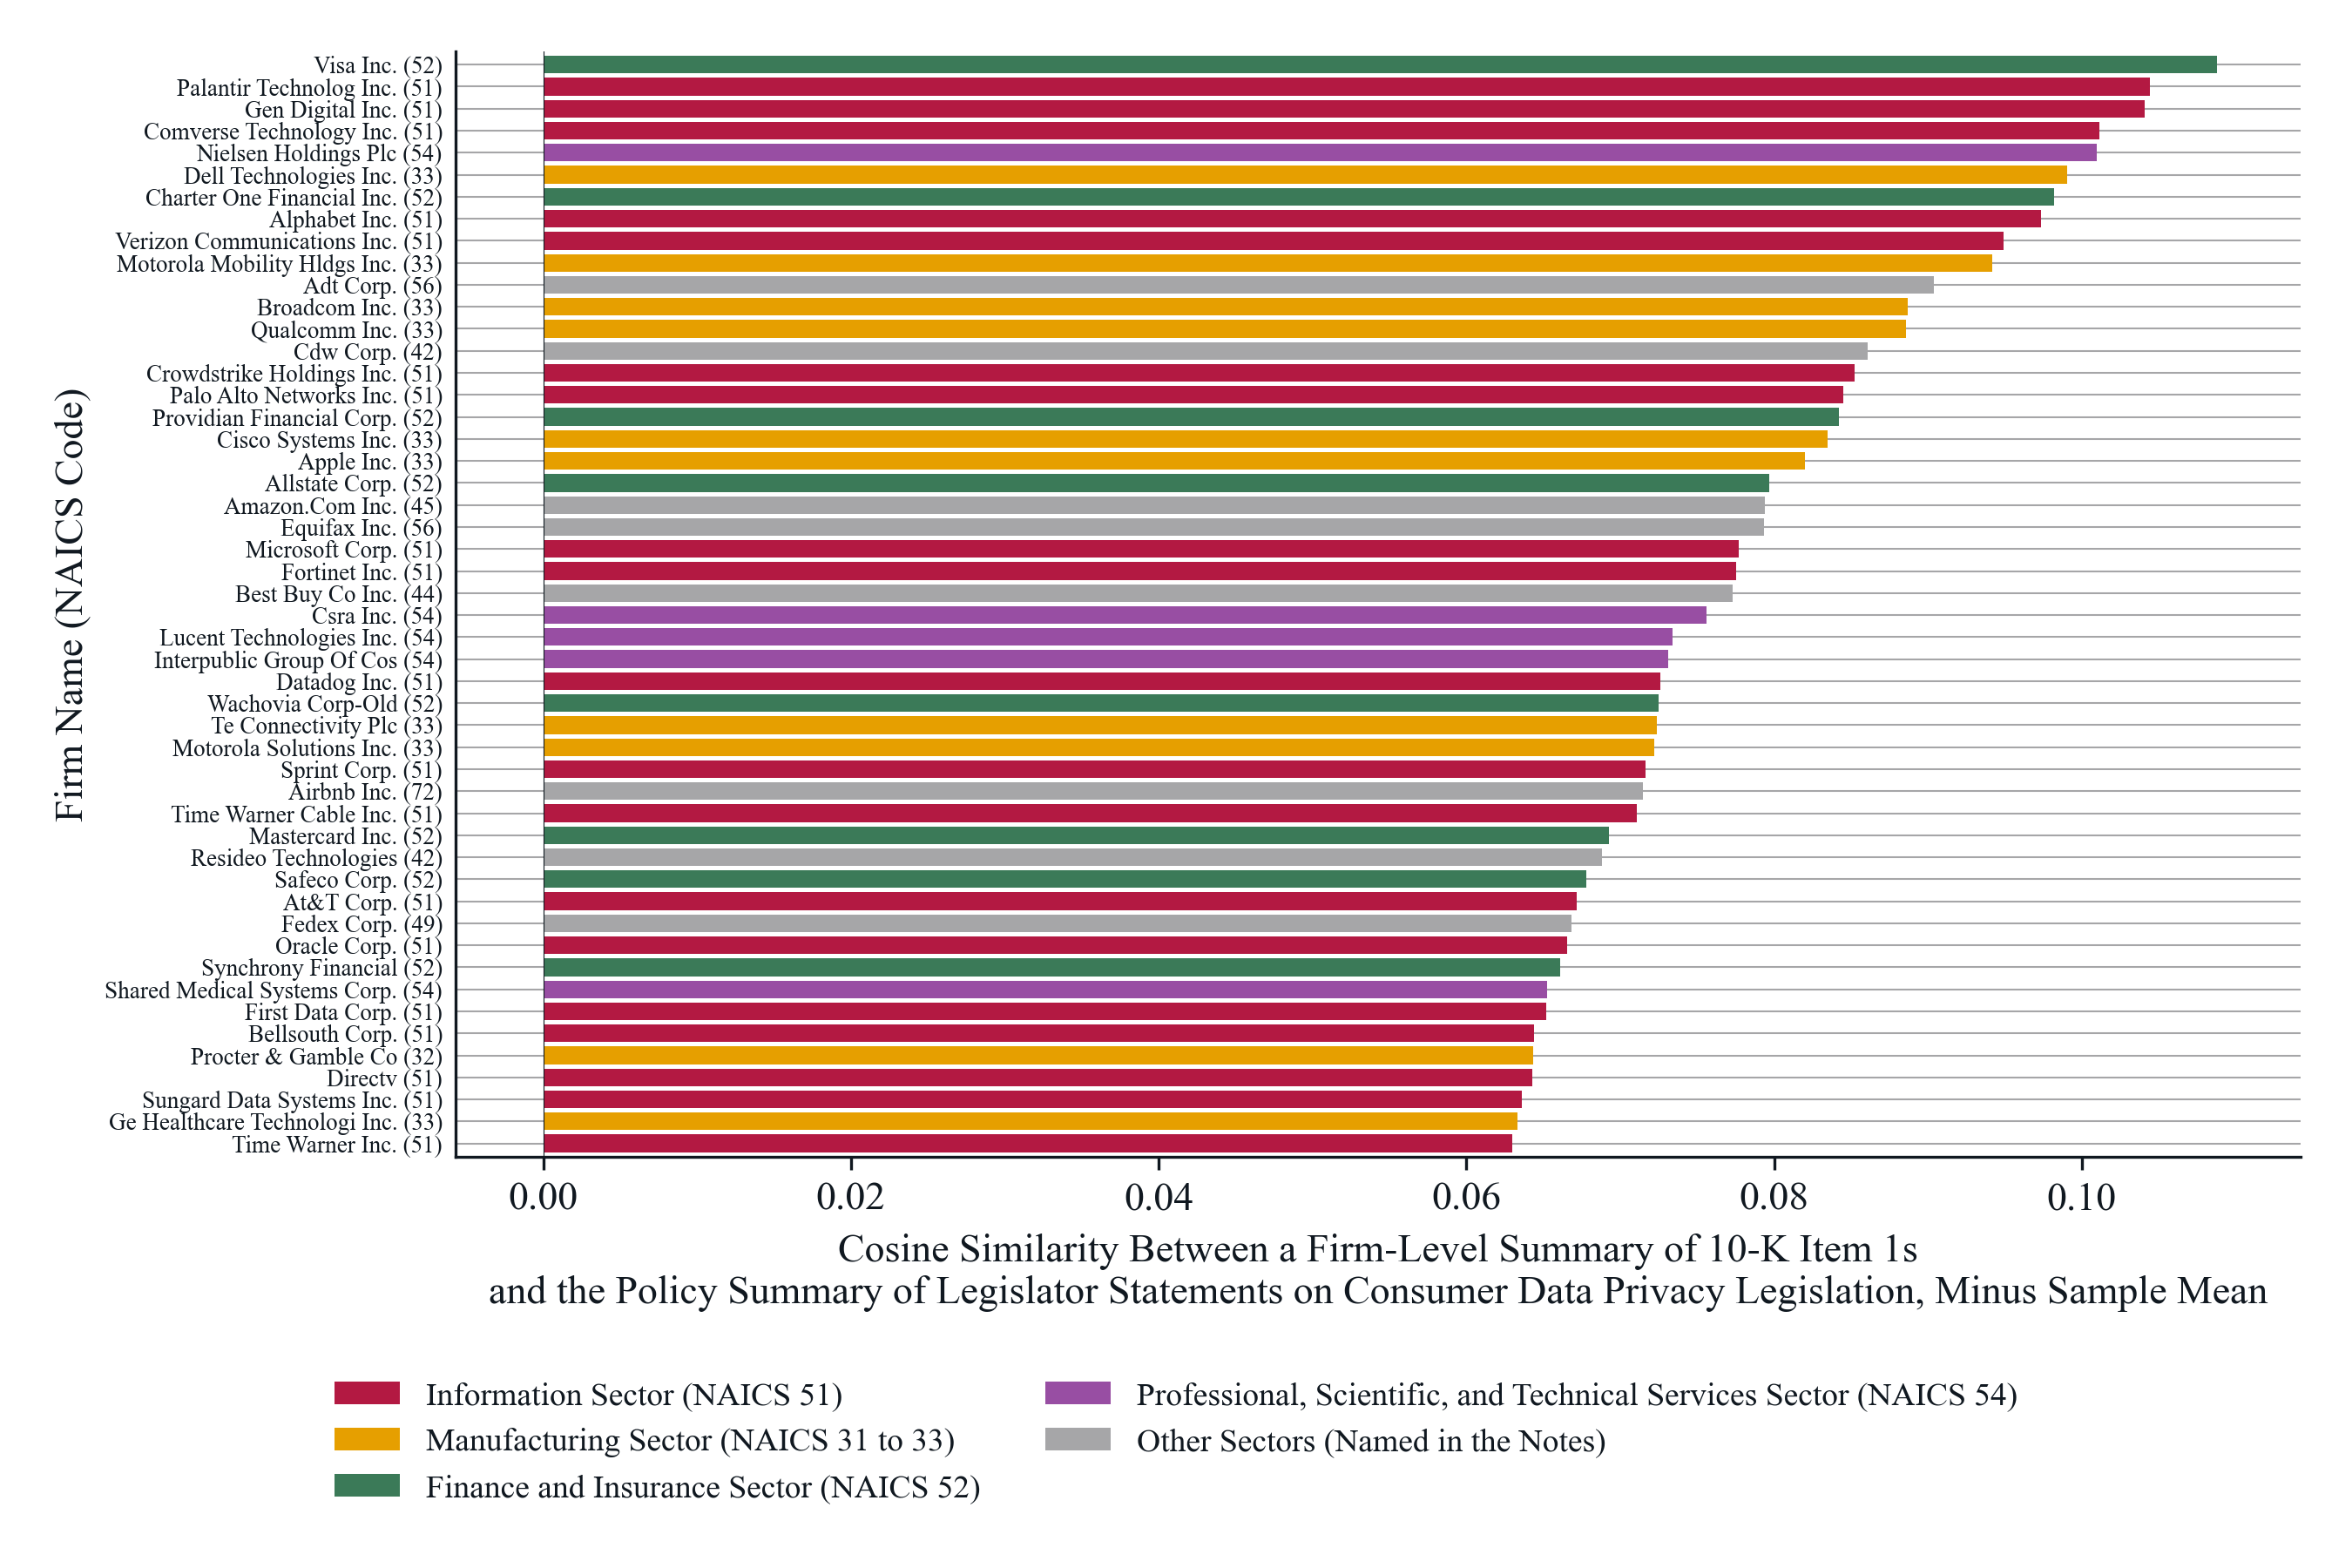

*Notes*: Each bar is the firm's score minus the sample mean, the mean over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.512: zero is the sample mean, a bar to the right is a firm above it and a bar to the left a firm below it. The 50 firms with the highest score are ordered from the highest at the top to the lowest at the bottom, and the horizontal range is the same in all four figures. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The tick label gives the firm's NAICS two-digit sector code from its Compustat NAICS code, and the bar color its two-digit sector; sectors with at least 3 of the 50 firms in this figure have their own color, at most 8 of them in order of firm count; at the two-digit level information, mining, manufacturing, and finance keep the colors of T3.9.2, and the other colors are assigned figure by figure. Sectors without a color of their own are drawn in grey as other sectors: Adt Corp. (administrative and support and waste management, NAICS 56); Cdw Corp. (wholesale trade, NAICS 42); Amazon.Com Inc. (retail trade, NAICS 45); Equifax Inc. (administrative and support and waste management, NAICS 56); Best Buy Co Inc. (retail trade, NAICS 44); Airbnb Inc. (accommodation and food services, NAICS 72); Resideo Technologies (wholesale trade, NAICS 42); Fedex Corp. (transportation and warehousing, NAICS 49). Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 2. The 50 Firms With the Lowest Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, Relative to the Sample Mean, by NAICS Two-Digit Sector**

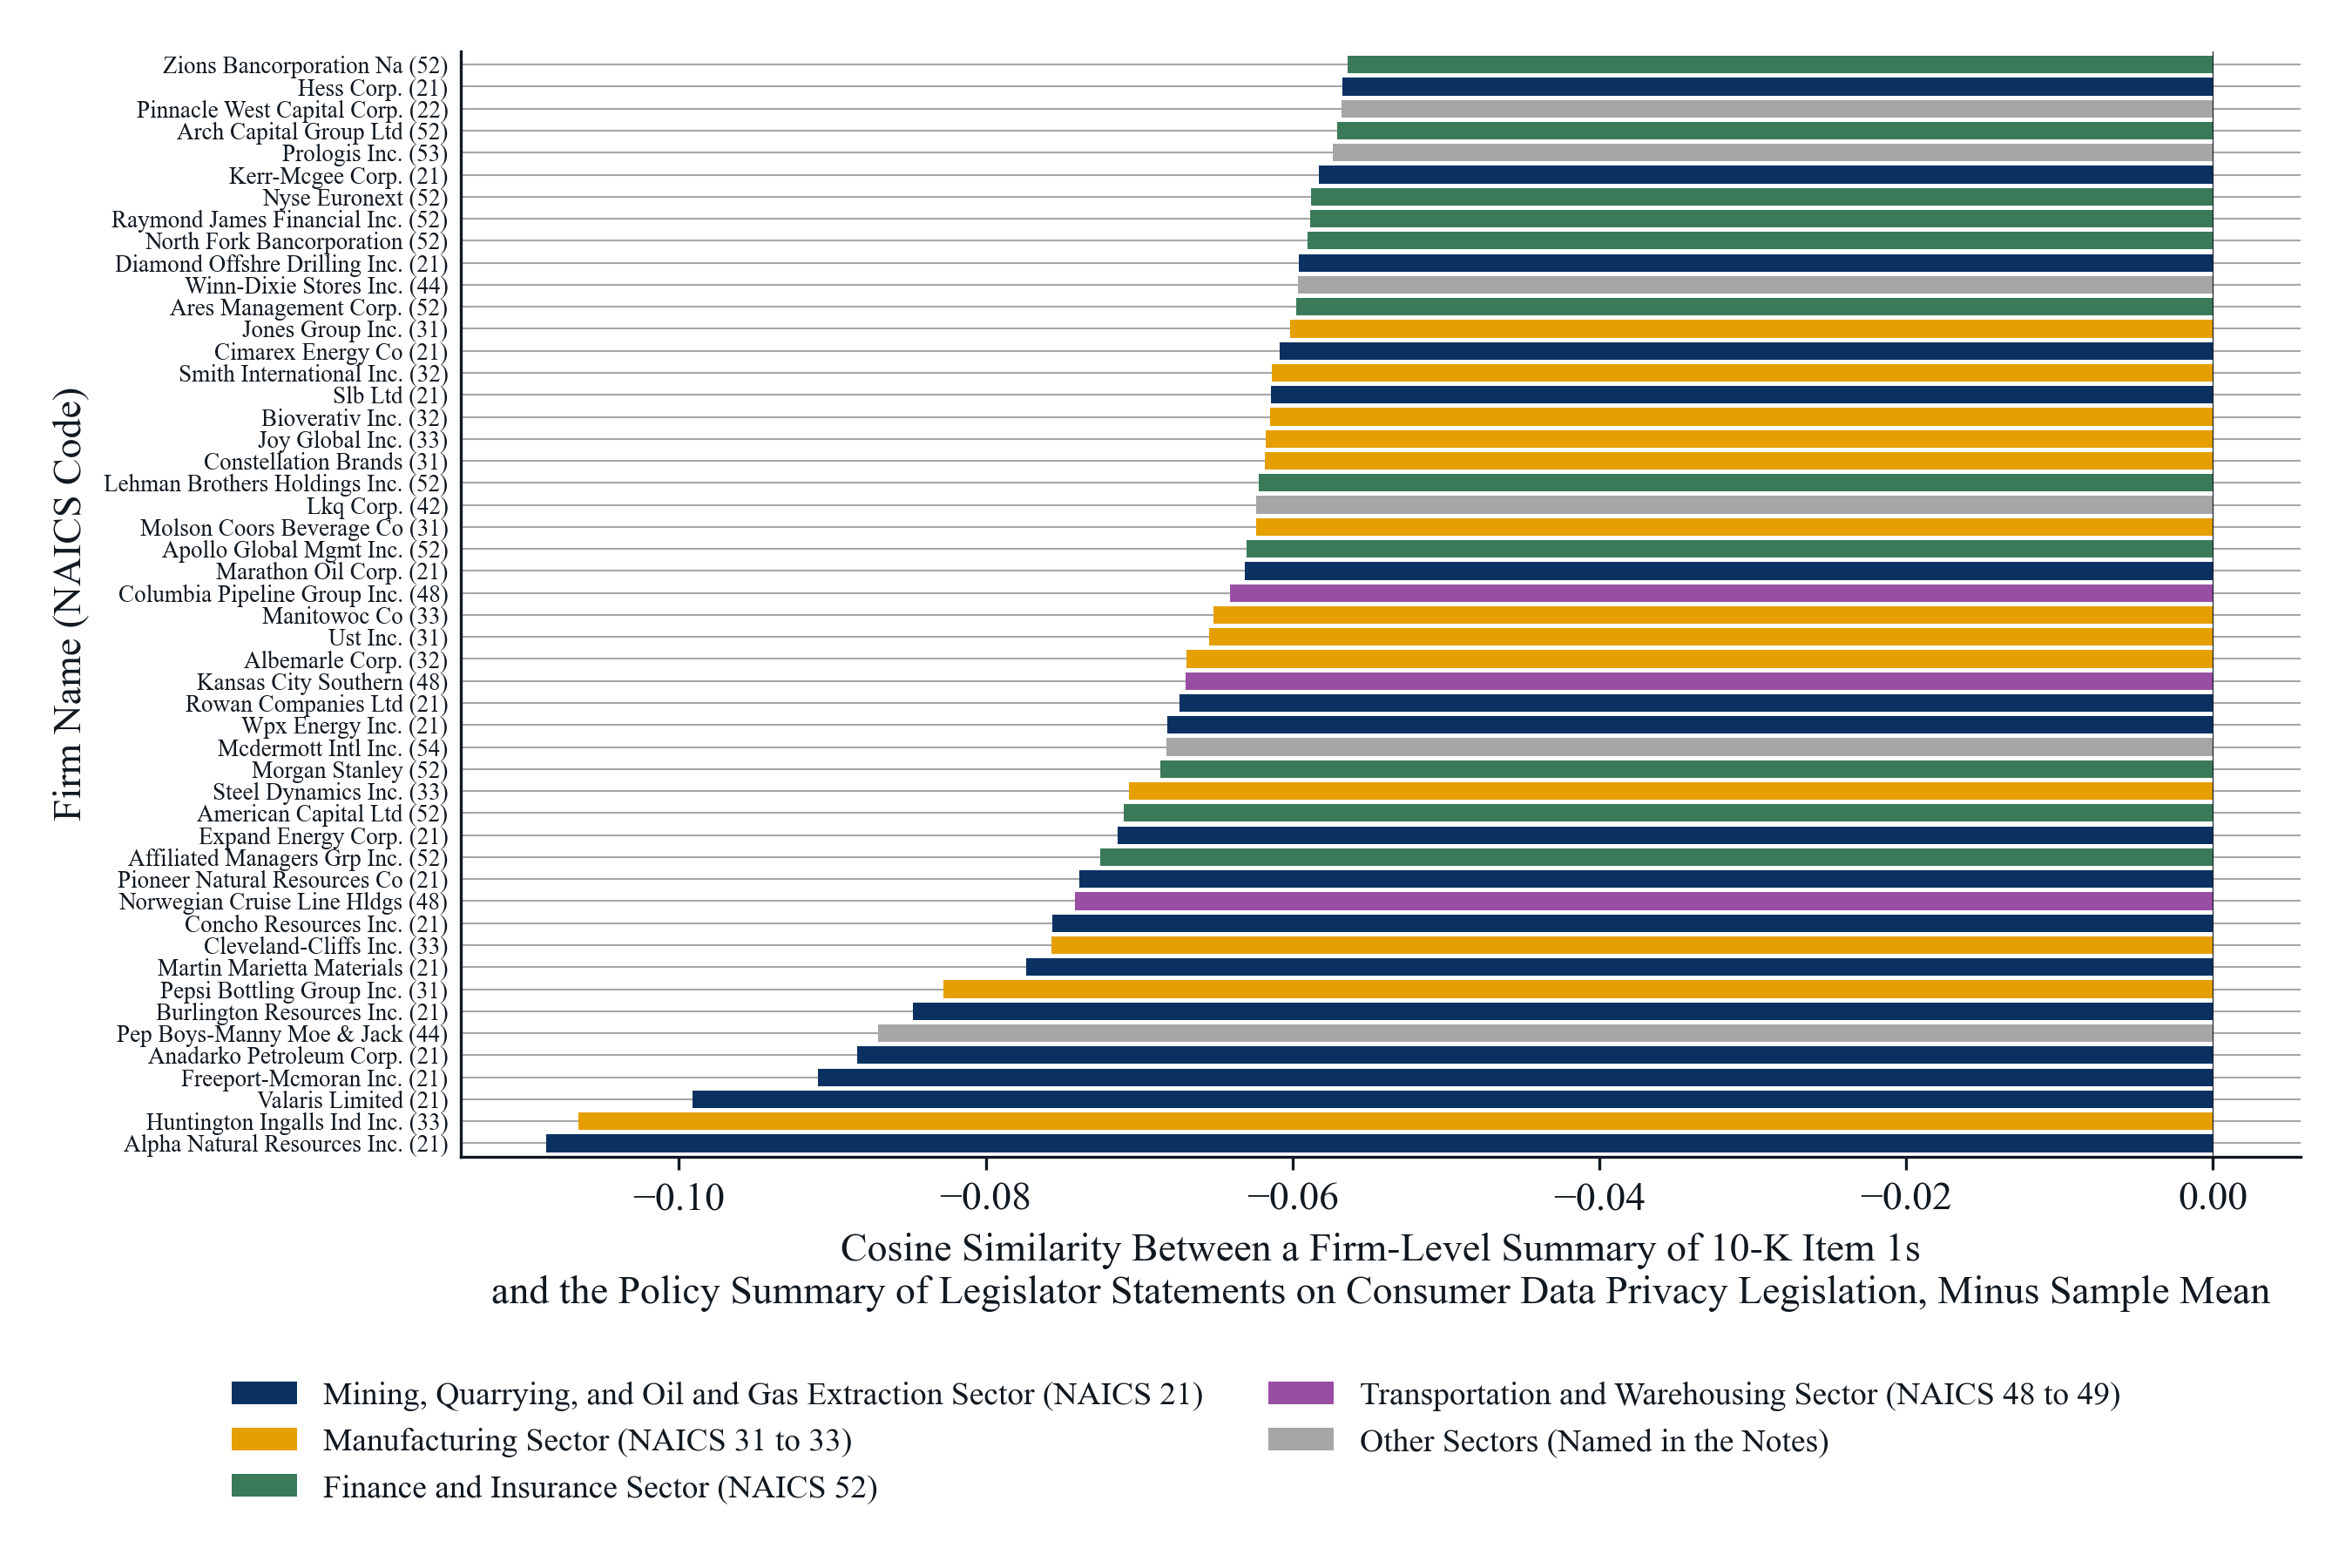

*Notes*: Each bar is the firm's score minus the sample mean, the mean over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.512: zero is the sample mean, a bar to the right is a firm above it and a bar to the left a firm below it. The 50 firms with the lowest score are ordered from the highest at the top to the lowest at the bottom, and the horizontal range is the same in all four figures. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The tick label gives the firm's NAICS two-digit sector code from its Compustat NAICS code, and the bar color its two-digit sector; sectors with at least 3 of the 50 firms in this figure have their own color, at most 8 of them in order of firm count; at the two-digit level information, mining, manufacturing, and finance keep the colors of T3.9.2, and the other colors are assigned figure by figure. Sectors without a color of their own are drawn in grey as other sectors: Pinnacle West Capital Corp. (utilities, NAICS 22); Prologis Inc. (real estate and rental and leasing, NAICS 53); Winn-Dixie Stores Inc. (retail trade, NAICS 44); Lkq Corp. (wholesale trade, NAICS 42); Mcdermott Intl Inc. (professional, scientific, and technical services, NAICS 54); Pep Boys-Manny Moe & Jack (retail trade, NAICS 44). Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 3. The 50 Firms With the Highest Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, Relative to the Sample Mean, by NAICS Three-Digit Subsector**

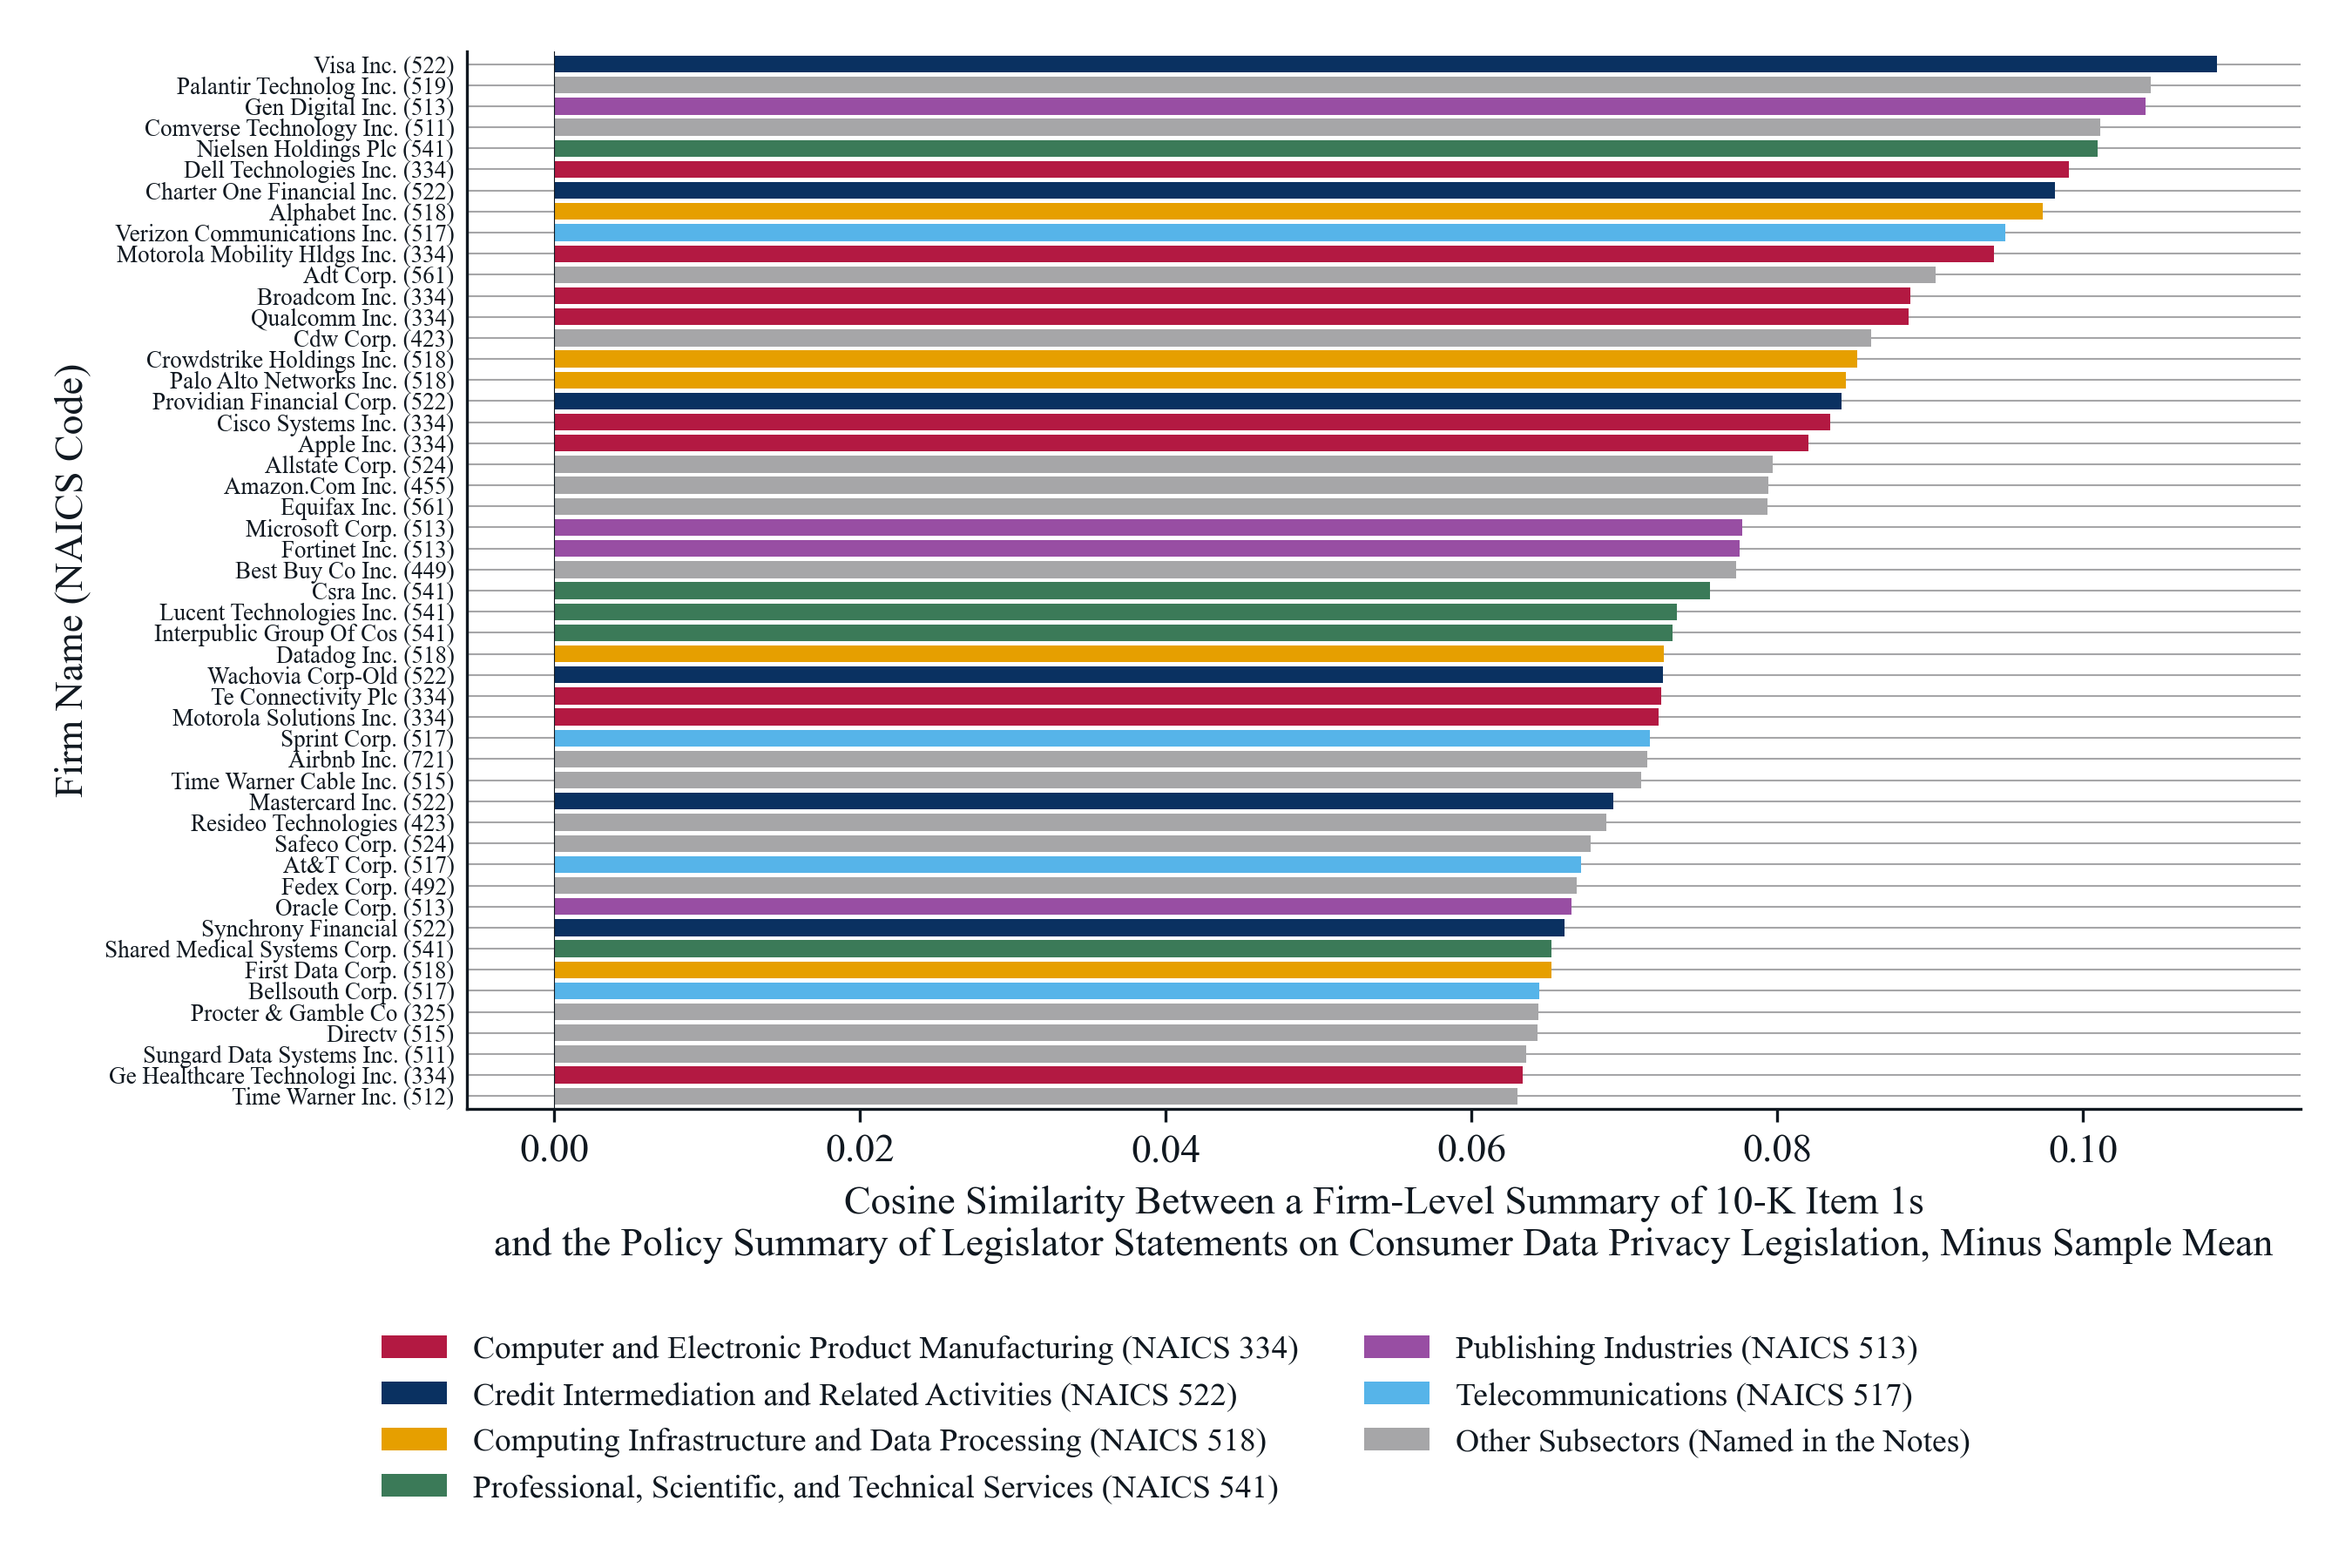

*Notes*: Each bar is the firm's score minus the sample mean, the mean over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.512: zero is the sample mean, a bar to the right is a firm above it and a bar to the left a firm below it. The 50 firms with the highest score are ordered from the highest at the top to the lowest at the bottom, and the horizontal range is the same in all four figures. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The tick label gives the firm's NAICS three-digit subsector code from its Compustat NAICS code, and the bar color its three-digit subsector; subsectors with at least 3 of the 50 firms in this figure have their own color, at most 8 of them in order of firm count; at the two-digit level information, mining, manufacturing, and finance keep the colors of T3.9.2, and the other colors are assigned figure by figure. Subsectors without a color of their own are drawn in grey as other subsectors: Palantir Technolog Inc. (web search portals and other information services, NAICS 519); Comverse Technology Inc. (publishing industries, except internet (naics 2017), NAICS 511); Adt Corp. (administrative and support services, NAICS 561); Cdw Corp. (merchant wholesalers, durable goods, NAICS 423); Allstate Corp. (insurance carriers and related activities, NAICS 524); Amazon.Com Inc. (general merchandise retailers, NAICS 455); Equifax Inc. (administrative and support services, NAICS 561); Best Buy Co Inc. (furniture, electronics, and appliance retailers, NAICS 449); Airbnb Inc. (accommodation, NAICS 721); Time Warner Cable Inc. (broadcasting, except internet (naics 2017), NAICS 515); Resideo Technologies (merchant wholesalers, durable goods, NAICS 423); Safeco Corp. (insurance carriers and related activities, NAICS 524); Fedex Corp. (couriers and messengers, NAICS 492); Procter & Gamble Co (chemical manufacturing, NAICS 325); Directv (broadcasting, except internet (naics 2017), NAICS 515); Sungard Data Systems Inc. (publishing industries, except internet (naics 2017), NAICS 511); Time Warner Inc. (motion picture and sound recording industries, NAICS 512). Subsector names are NAICS 2022 names, shortened; a code that exists only in an older NAICS vintage carries that vintage's name. Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 4. The 50 Firms With the Lowest Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, Relative to the Sample Mean, by NAICS Three-Digit Subsector**

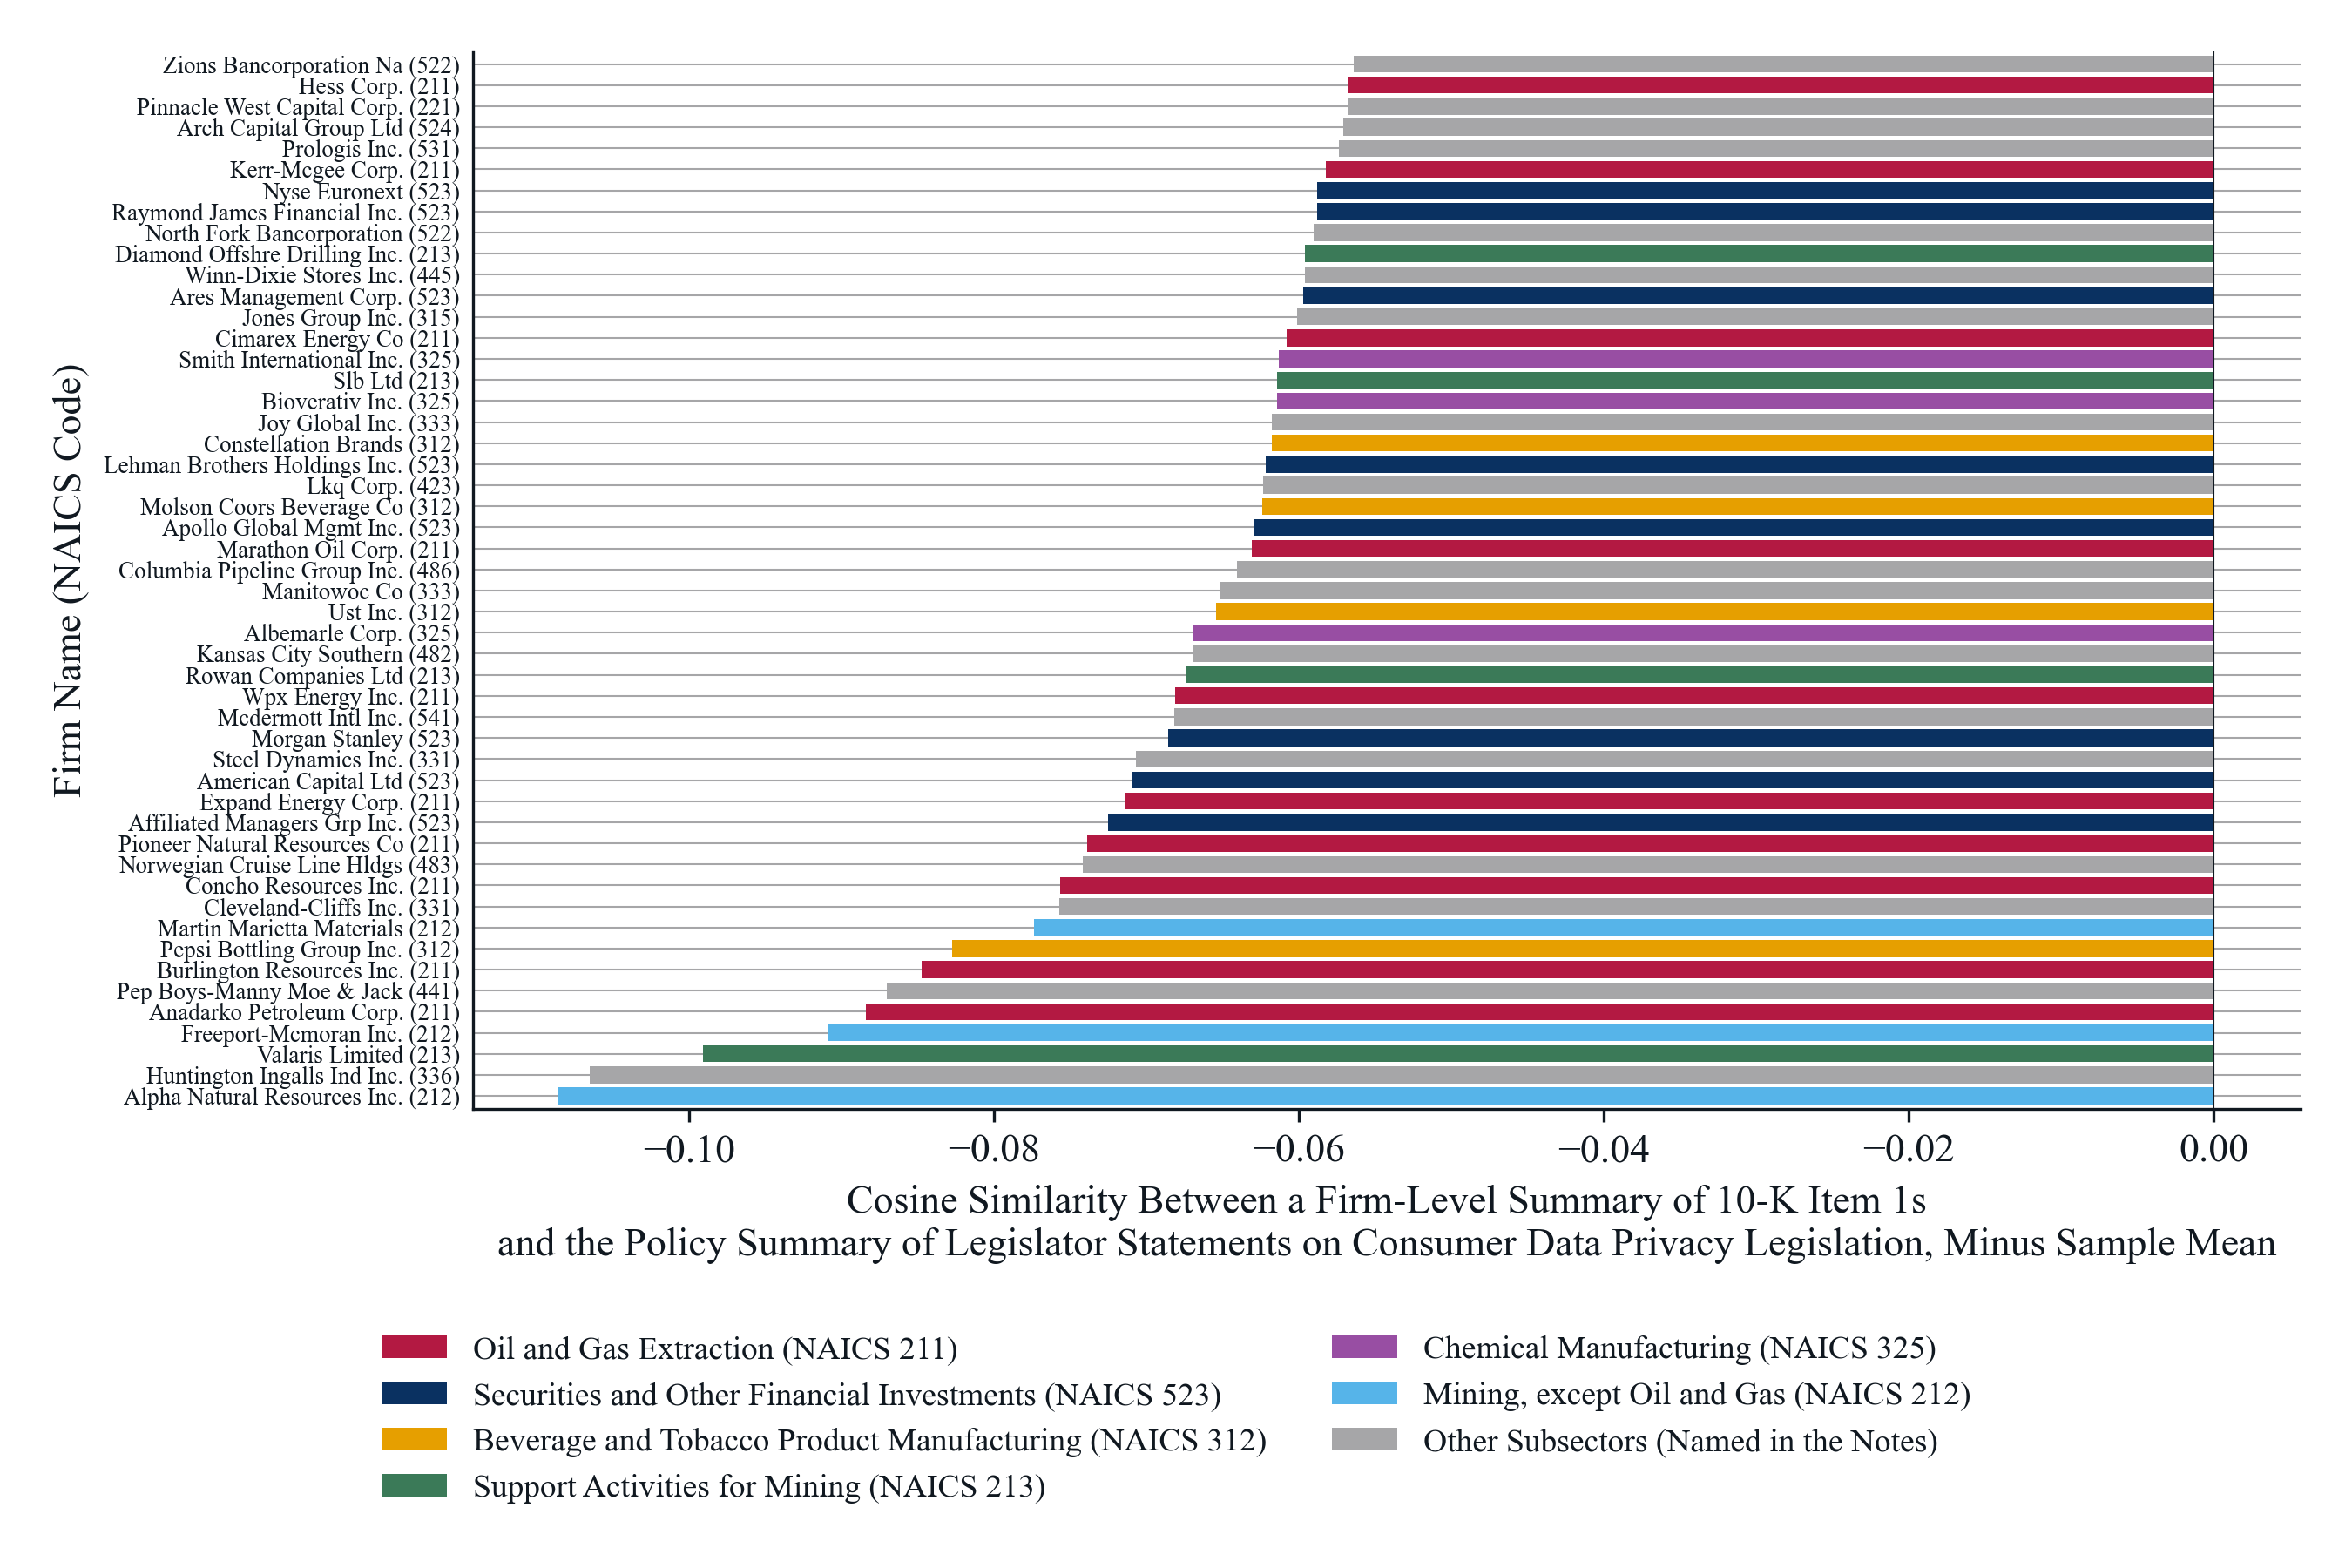

*Notes*: Each bar is the firm's score minus the sample mean, the mean over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.512: zero is the sample mean, a bar to the right is a firm above it and a bar to the left a firm below it. The 50 firms with the lowest score are ordered from the highest at the top to the lowest at the bottom, and the horizontal range is the same in all four figures. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The tick label gives the firm's NAICS three-digit subsector code from its Compustat NAICS code, and the bar color its three-digit subsector; subsectors with at least 3 of the 50 firms in this figure have their own color, at most 8 of them in order of firm count; at the two-digit level information, mining, manufacturing, and finance keep the colors of T3.9.2, and the other colors are assigned figure by figure. Subsectors without a color of their own are drawn in grey as other subsectors: Zions Bancorporation Na (credit intermediation and related activities, NAICS 522); Pinnacle West Capital Corp. (utilities, NAICS 221); Arch Capital Group Ltd (insurance carriers and related activities, NAICS 524); Prologis Inc. (real estate, NAICS 531); North Fork Bancorporation (credit intermediation and related activities, NAICS 522); Winn-Dixie Stores Inc. (food and beverage retailers, NAICS 445); Jones Group Inc. (apparel manufacturing, NAICS 315); Joy Global Inc. (machinery manufacturing, NAICS 333); Lkq Corp. (merchant wholesalers, durable goods, NAICS 423); Columbia Pipeline Group Inc. (pipeline transportation, NAICS 486); Manitowoc Co (machinery manufacturing, NAICS 333); Kansas City Southern (rail transportation, NAICS 482); Mcdermott Intl Inc. (professional, scientific, and technical services, NAICS 541); Steel Dynamics Inc. (primary metal manufacturing, NAICS 331); Norwegian Cruise Line Hldgs (water transportation, NAICS 483); Cleveland-Cliffs Inc. (primary metal manufacturing, NAICS 331); Pep Boys-Manny Moe & Jack (motor vehicle and parts dealers, NAICS 441); Huntington Ingalls Ind Inc. (transportation equipment manufacturing, NAICS 336). Subsector names are NAICS 2022 names, shortened; a code that exists only in an older NAICS vintage carries that vintage's name. Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [7]:
from IPython.display import Image, display
display(Image(filename=OUTPUT_FOLDER / "fig_selected_high_and_low_relevance_firms_by_sector.png"))